## 1. Assignment -7-

**Concise Assignment Brief: Naïve Bayes and Decision Trees (ML Systems)**

## 2. Concise Assignment Brief

In this assignment, you will develop and compare two classification pipelines—Decision Trees and Naïve Bayes—in a realistic ML systems setting for quality screening in a winery. The objective is to flag potentially *high-quality* red wines using routinely collected physicochemical measurements, while demonstrating disciplined experimental practice: reproducible splits, leakage-aware preprocessing, and evidence-based model selection.

## 3. Dataset
You will use the **UCI Wine Quality (Red)** dataset, consisting of approximately **1,599** wine samples with **11 numeric features** (e.g., acidity, residual sugar, sulphates, alcohol) and an integer **quality score** (0–10). You will convert the quality score into a **binary target** (e.g., “high quality” vs “not high quality”) and justify your threshold choice in terms of class balance and the operational cost of false positives vs false negatives.

- Dataset page: https://archive.ics.uci.edu/dataset/186/wine%2Bquality
- Direct CSV: https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv
- Licensing/usage note: **CC BY 4.0** (cite the dataset page in your notebook).

## 4. Machine Learning Tasks
Your workflow must include: 
1. data loading and lightweight validation (schema, missingness, duplicates), (ii) exploratory analysis with at least two plots, 
2. preprocessing using a scikit-learn `Pipeline` that includes `StandardScaler` for comparability and consistent interfaces, 
3. training and evaluating a **baseline** `DecisionTreeClassifier` and an appropriate **Naïve Bayes** model (e.g., `GaussianNB`), and 
4. at least one **diagnostic** beyond a confusion matrix (e.g., learning curve) to reason about bias/variance and data sufficiency. You will also conduct brief error analysis by inspecting misclassified cases or feature regimes.

## 5.Deliverables 

1. an executed Jupyter notebook with code, plots, and concise written answers embedded in Markdown
2. a short systems reflection addressing reproducibility (what you log), leakage prevention, inference-time compute/latency considerations, and a monitoring/drift plan (specific signals and alert logic).
3. Optional appendix cell: experiment log table (parameters, seeds, metrics, timestamps).


## 6  Grading Rubric (100 points)

| Category | Points | Criteria |
|---|---:|---|
| Code correctness & completeness | 35 | Notebook runs end-to-end; correct use of scikit-learn APIs; pipelines implemented; required components present. |
| Data exploration & preprocessing quality | 15 | EDA is meaningful; ≥2 plots; preprocessing is appropriate and justified (incl. scaling). |
| Modeling & evaluation rigor | 20 | Proper split with `stratify` and `random_state`; metrics reported; confusion matrix + one additional diagnostic; fair comparison across models. |
| Interpretation & error analysis | 15 | Correct interpretation of metrics/plots; identifies plausible failure modes; targeted error analysis is coherent. |
| ML systems thinking | 10 | Clear discussion of reproducibility, leakage risks, monitoring/drift, and compute/latency tradeoffs. |
| Reproducibility & presentation | 5 | Clear organization; key choices documented; dataset citation included; results are easy to audit. |


__________________________________________________________________________________________________________________________________________________________________________________

## Assignment Brief

The goal is to predict whether a red wine is high quality using its physicochemical measurements. I will compare a Decision Tree with Gaussian Naïve Bayes and evaluate their performance using the same train/test split.

## Dataset

This assignment uses the UCI Wine Quality (Red) dataset. The dataset contains 1,599 wine samples with 11 numeric features and a quality score from 0 to 10. I usually define high quality as a quality score of 7 or higher.

In [3]:
# Imports and reproducibility

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    learning_curve
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

print("Random seed:", RANDOM_STATE)
print("pandas version:", pd.__version__)

Random seed: 42
pandas version: 2.3.3


## Data Loading

The dataset is loaded directly from the UCI repository.

In [4]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

wine = pd.read_csv(DATA_URL, sep=";")

print("Shape:", wine.shape)
display(wine.head())

Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Data Validation

I checked the data types, missing values, duplicates, and basic value ranges.

In [5]:
print("Data types:")
print(wine.dtypes)

print("\nMissing values:")
print(wine.isna().sum())

print("\nDuplicate rows:", wine.duplicated().sum())

print("\nSummary:")
display(wine.describe())

Data types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicate rows: 240

Summary:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [6]:
# Basic range checks

print("Quality range:", wine["quality"].min(), "to", wine["quality"].max())
print("Alcohol range:", wine["alcohol"].min(), "to", wine["alcohol"].max())

assert wine["quality"].between(0, 10).all()
assert wine.isna().sum().sum() == 0

print("Validation checks passed.")

Quality range: 3 to 8
Alcohol range: 8.4 to 14.9
Validation checks passed.


## Define the Target

A wine with a quality score of 7 or higher is labeled as high quality. This creates a binary classification problem.

In [7]:
wine["high_quality"] = (wine["quality"] >= 7).astype(int)

print("Class counts:")
print(wine["high_quality"].value_counts())

print("\nClass proportions:")
print(wine["high_quality"].value_counts(normalize=True))

Class counts:
high_quality
0    1382
1     217
Name: count, dtype: int64

Class proportions:
high_quality
0    0.86429
1    0.13571
Name: proportion, dtype: float64


### Target Choice

I used 7 as the cutoff because it represents a relatively high quality score. The positive class is smaller than the negative class, so accuracy alone will not be enough to judge the models.

## Exploratory Data Analysis

The plots below show the distribution of wine quality and the relationship between alcohol and quality.

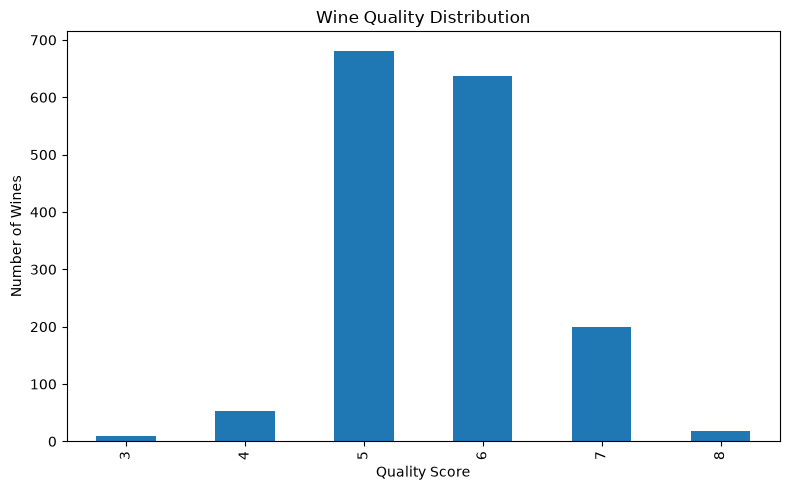

In [8]:
plt.figure(figsize=(8, 5))

wine["quality"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Quality Score")
plt.ylabel("Number of Wines")
plt.title("Wine Quality Distribution")
plt.tight_layout()
plt.show()

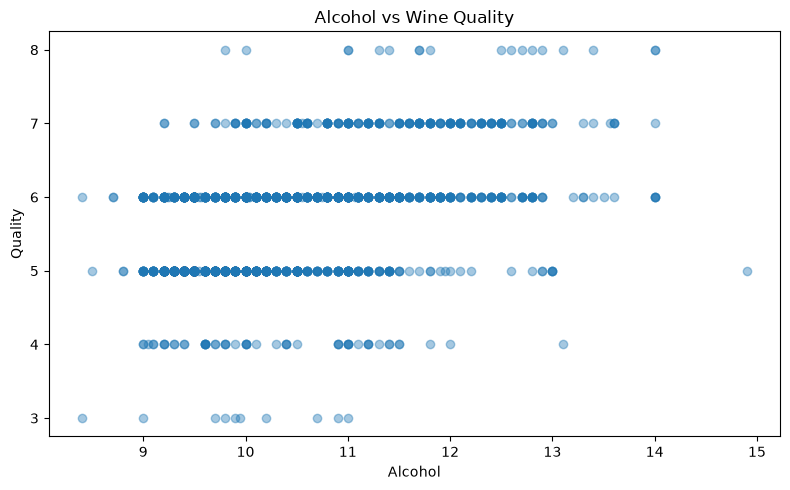

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    wine["alcohol"],
    wine["quality"],
    alpha=0.4
)

plt.xlabel("Alcohol")
plt.ylabel("Quality")
plt.title("Alcohol vs Wine Quality")
plt.tight_layout()
plt.show()

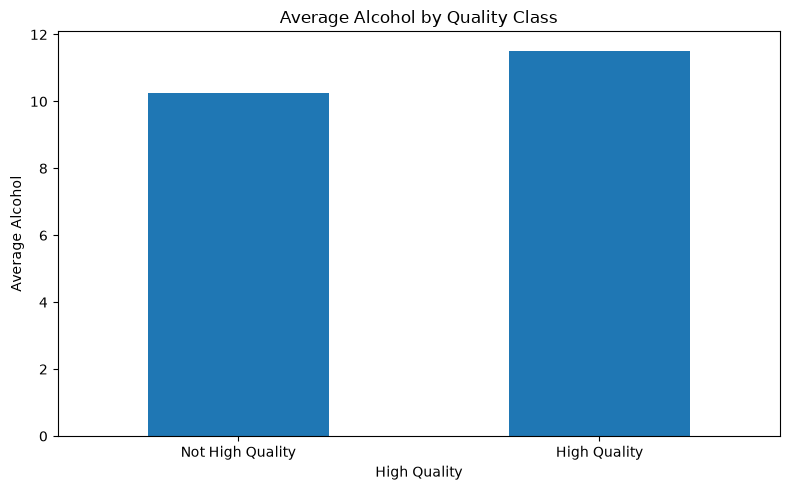

In [10]:
plt.figure(figsize=(8, 5))

wine.groupby("high_quality")["alcohol"].mean().plot(kind="bar")

plt.xlabel("High Quality")
plt.ylabel("Average Alcohol")
plt.title("Average Alcohol by Quality Class")
plt.xticks([0, 1], ["Not High Quality", "High Quality"], rotation=0)
plt.tight_layout()
plt.show()

### EDA Interpretation

Most wines are in the middle quality range, while high-quality wines are less common. Alcohol appears to have some relationship with quality, but there is a lot of overlap. This suggests that several features are needed rather than relying on one measurement.

## Train/Test Split

The quality score is removed from the features because it is used to create the target. I use a stratified split so both sets have a similar class distribution.

In [11]:
X = wine.drop(columns=["quality", "high_quality"])
y = wine["high_quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True))

Training rows: 1279
Testing rows: 320

Training class distribution:
high_quality
0    0.863956
1    0.136044
Name: proportion, dtype: float64

Testing class distribution:
high_quality
0    0.865625
1    0.134375
Name: proportion, dtype: float64


## Preprocessing

All features are numeric, so I use median imputation and StandardScaler. The preprocessing is inside the pipelines so it is fit using the training data only.

In [12]:
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## Decision Tree

The Decision Tree is used as the first classification model. It does not require scaled features, but keeping the preprocessing pipeline consistent makes the model setup easier to reproduce.

In [13]:
dt_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ))
])

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree Results")
print(classification_report(y_test, dt_pred, zero_division=0))

Decision Tree Results
              precision    recall  f1-score   support

           0       0.95      0.94      0.95       277
           1       0.64      0.70      0.67        43

    accuracy                           0.91       320
   macro avg       0.80      0.82      0.81       320
weighted avg       0.91      0.91      0.91       320



## Decision Tree Confusion Matrix

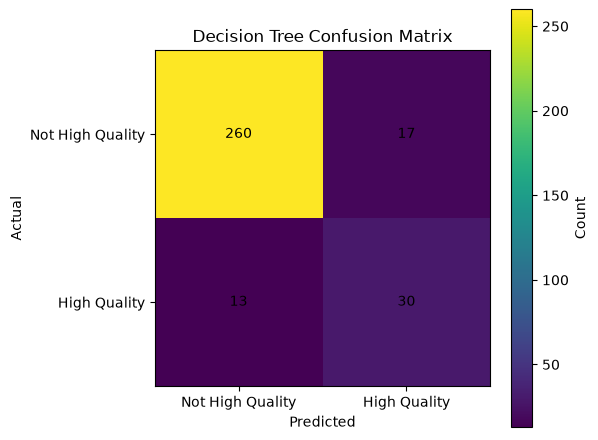

In [14]:
dt_cm = confusion_matrix(y_test, dt_pred)

plt.figure(figsize=(6, 5))
plt.imshow(dt_cm)

plt.xticks([0, 1], ["Not High Quality", "High Quality"])
plt.yticks([0, 1], ["Not High Quality", "High Quality"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.colorbar(label="Count")

for i in range(2):
    for j in range(2):
        plt.text(j, i, dt_cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

## Gaussian Naïve Bayes

Gaussian Naïve Bayes is a good comparison because the features are continuous numeric measurements. It assumes the features are conditionally independent within each class.

In [15]:
nb_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", GaussianNB())
])

nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_test)
nb_prob = nb_model.predict_proba(X_test)[:, 1]

print("Gaussian Naïve Bayes Results")
print(classification_report(y_test, nb_pred, zero_division=0))

Gaussian Naïve Bayes Results
              precision    recall  f1-score   support

           0       0.95      0.88      0.92       277
           1       0.48      0.72      0.58        43

    accuracy                           0.86       320
   macro avg       0.72      0.80      0.75       320
weighted avg       0.89      0.86      0.87       320



## Naïve Bayes Confusion Matrix

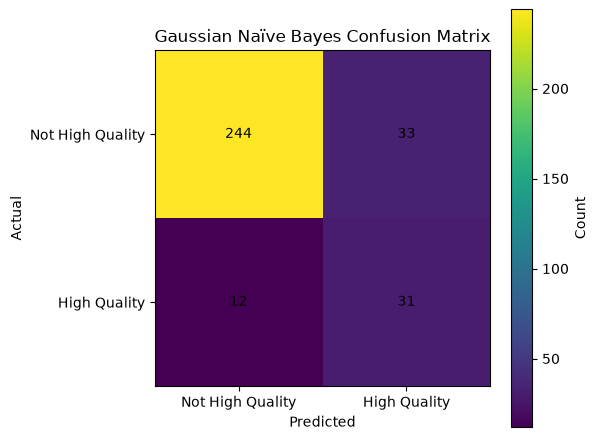

In [16]:
nb_cm = confusion_matrix(y_test, nb_pred)

plt.figure(figsize=(6, 5))
plt.imshow(nb_cm)

plt.xticks([0, 1], ["Not High Quality", "High Quality"])
plt.yticks([0, 1], ["Not High Quality", "High Quality"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Gaussian Naïve Bayes Confusion Matrix")
plt.colorbar(label="Count")

for i in range(2):
    for j in range(2):
        plt.text(j, i, nb_cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

## Model Comparison

I compare accuracy, precision, recall, F1, and ROC-AUC. Recall is important because missing a high-quality wine could be more costly than incorrectly flagging a lower-quality wine.

In [17]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Gaussian Naive Bayes"
    ],
    "Accuracy": [
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, nb_pred)
    ],
    "Precision": [
        precision_score(y_test, dt_pred, zero_division=0),
        precision_score(y_test, nb_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, dt_pred, zero_division=0),
        recall_score(y_test, nb_pred, zero_division=0)
    ],
    "F1": [
        f1_score(y_test, dt_pred, zero_division=0),
        f1_score(y_test, nb_pred, zero_division=0)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, dt_prob),
        roc_auc_score(y_test, nb_prob)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Decision Tree,0.906250,0.638298,0.697674,0.666667,0.818151
1,Gaussian Naive Bayes,0.859375,0.484375,0.720930,0.579439,0.851734


## Learning Curve

The learning curve shows how model performance changes as more training data is used. This helps identify possible high variance, high bias, or whether more data could help.

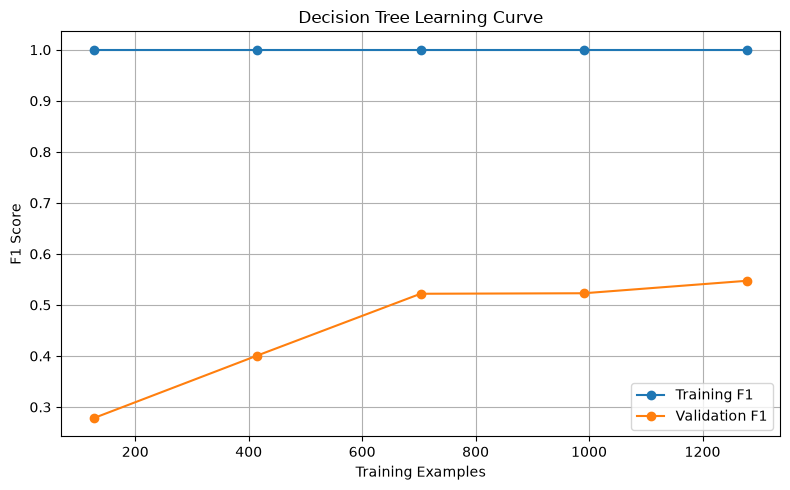

In [18]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

train_sizes, train_scores, val_scores = learning_curve(
    dt_model,
    X,
    y,
    cv=cv,
    scoring="f1",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

plt.figure(figsize=(8, 5))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training F1"
)

plt.plot(
    train_sizes,
    val_mean,
    marker="o",
    label="Validation F1"
)

plt.xlabel("Training Examples")
plt.ylabel("F1 Score")
plt.title("Decision Tree Learning Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Learning Curve Interpretation

If the training score is much higher than the validation score, the tree is likely overfitting. If both scores are low and close together, the model may have high bias. More training data could help if the validation score is still improving at the end of the curve.

## Error Analysis

I will inspect cases where the Decision Tree incorrectly classified the wine.

In [19]:
error_analysis = X_test.copy()

error_analysis["actual"] = y_test
error_analysis["predicted"] = dt_pred
error_analysis["probability"] = dt_prob

errors = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
].copy()

print("Number of errors:", len(errors))

display(
    errors.sort_values(
        "probability",
        ascending=False
    ).head(10)
)

Number of errors: 30


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,actual,predicted,probability
1176,6.5,0.880,0.03,5.6,0.079,23.0,47.0,0.99572,3.58,0.50,11.2,0,1,1.0
989,9.7,0.295,0.40,1.5,0.073,14.0,21.0,0.99556,3.14,0.51,10.9,0,1,1.0
1124,6.5,0.580,0.00,2.2,0.096,3.0,13.0,0.99557,3.62,0.62,11.5,0,1,1.0
1377,5.2,0.490,0.26,2.3,0.090,23.0,74.0,0.99530,3.71,0.62,12.2,0,1,1.0
69,8.0,0.705,0.05,1.9,0.074,8.0,19.0,0.99620,3.34,0.95,10.5,0,1,1.0
982,7.3,0.520,0.32,2.1,0.070,51.0,70.0,0.99418,3.34,0.82,12.9,0,1,1.0
316,9.6,0.560,0.23,3.4,0.102,37.0,92.0,0.99960,3.30,0.65,10.1,0,1,1.0
372,9.1,0.280,0.48,1.8,0.067,26.0,46.0,0.99670,3.32,1.04,10.6,0,1,1.0
544,14.3,0.310,0.74,1.8,0.075,6.0,15.0,1.00080,2.86,0.79,8.4,0,1,1.0
870,7.7,0.715,0.01,2.1,0.064,31.0,43.0,0.99371,3.41,0.57,11.8,0,1,1.0


### Error Analysis Interpretation

The misclassified wines show that some wines have feature values that overlap between the two quality groups. This makes the classification difficult because high-quality wines do not have one clear set of measurements.

## Decision Tree Complexity

A very large tree can fit the training data closely but may generalize poorly.

In [20]:
fitted_dt = dt_model.named_steps["model"]

print("Tree depth:", fitted_dt.get_depth())
print("Number of leaves:", fitted_dt.get_n_leaves())

Tree depth: 14
Number of leaves: 123


### Complexity Interpretation

A deeper tree has more decision rules and can be harder to explain. If the tree is much more accurate on training data than validation data, reducing its depth or increasing the minimum leaf size would be worth testing.

## Decision Tree Tuning

I will test a few tree depths to see whether a simpler tree generalizes better.

In [21]:
depths = [2, 3, 4, 5, 6, 8, 10, None]

tuning_results = []

for depth in depths:
    model = Pipeline([
        ("preprocessing", preprocessor),
        ("model", DecisionTreeClassifier(
            max_depth=depth,
            random_state=RANDOM_STATE
        ))
    ])
    
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    
    tuning_results.append({
        "max_depth": depth,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0)
    })

tuning_results = pd.DataFrame(tuning_results)

tuning_results

,max_depth,accuracy,precision,recall,f1
0,2.0,0.909375,0.791667,0.441860,0.567164
1,3.0,0.878125,0.833333,0.116279,0.204082
2,4.0,0.934375,0.805556,0.674419,0.734177
3,5.0,0.918750,0.729730,0.627907,0.675000
4,6.0,0.918750,0.707317,0.674419,0.690476
5,8.0,0.918750,0.697674,0.697674,0.697674
6,10.0,0.906250,0.632653,0.720930,0.673913
7,NaN,0.906250,0.638298,0.697674,0.666667


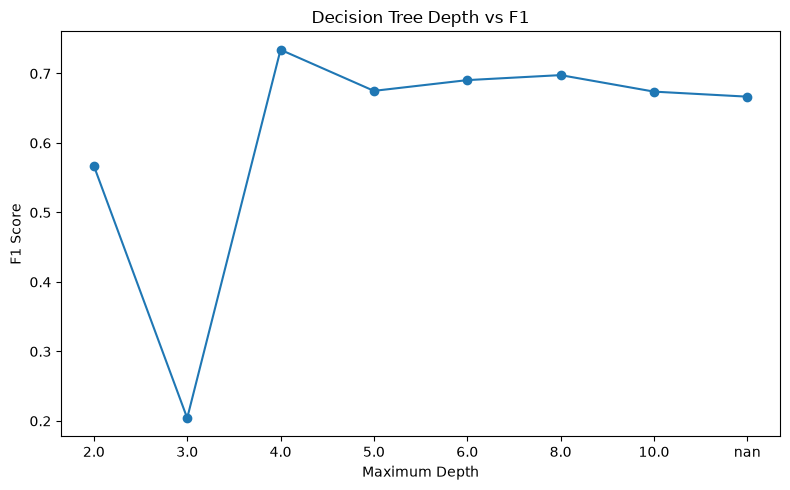

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    tuning_results["max_depth"].astype(str),
    tuning_results["f1"],
    marker="o"
)

plt.xlabel("Maximum Depth")
plt.ylabel("F1 Score")
plt.title("Decision Tree Depth vs F1")
plt.tight_layout()
plt.show()

### Tuning Interpretation

A very deep tree can overfit the training data. I would prefer a simpler tree if its F1 score is close to the best model because it is easier to explain and maintain.

## Final Model Choice

The final choice should not be based on accuracy alone. Since the goal is to identify high-quality wines, recall and F1 are useful when comparing the models.

In [23]:
best_model = results.loc[
    results["F1"].idxmax(),
    "Model"
]

print("Best model by F1:", best_model)

results.sort_values("F1", ascending=False)

Best model by F1: Decision Tree


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Decision Tree,0.906250,0.638298,0.697674,0.666667,0.818151
1,Gaussian Naive Bayes,0.859375,0.484375,0.720930,0.579439,0.851734


## Reproducibility

The experiment uses a fixed random seed and stratified train/test split. The dataset source, preprocessing steps, model parameters, metrics, and software versions should be saved with the experiment.

In [24]:
import sklearn
import sys

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Random state:", RANDOM_STATE)
print("Dataset shape:", wine.shape)

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
NumPy: 2.5.3
pandas: 2.3.3
scikit-learn: 1.9.1
Random state: 42
Dataset shape: (1599, 13)


## ML Systems Reflection

### Reproducibility

I would log the dataset source or hash, random seed, train/test split, preprocessing settings, model parameters, metrics, and software versions.

### Leakage

The target quality score is removed before training. Preprocessing is also inside the pipeline so it is learned from the training data only.

### Inference Cost

Both models are relatively lightweight. Naïve Bayes is especially fast, while a small Decision Tree also has low prediction cost.

### Monitoring

I would monitor feature distributions, missing values, prediction rates, and model performance. A large change in the input data or a drop in recall or F1 could indicate drift.

### Model Selection

The better model depends on the goal. If the Decision Tree has better recall and similar overall performance, it may be preferable because its decisions are easier to explain. If Naïve Bayes performs similarly while being simpler and faster, it could also be a reasonable choice.

## Final Results Summary

The Decision Tree and Gaussian Naïve Bayes models were trained using the same stratified split and preprocessing approach. The models were compared using accuracy, precision, recall, F1, and ROC-AUC. The learning curve and error analysis helped identify whether the models were overfitting and where their predictions were less reliable. For a production system, I would use the validation results along with interpretability, inference cost, and monitoring requirements before selecting the final model.

In [25]:
experiment_log = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Gaussian Naive Bayes"
    ],
    "Random_State": [
        RANDOM_STATE,
        RANDOM_STATE
    ],
    "Accuracy": [
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, nb_pred)
    ],
    "Precision": [
        precision_score(y_test, dt_pred, zero_division=0),
        precision_score(y_test, nb_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, dt_pred, zero_division=0),
        recall_score(y_test, nb_pred, zero_division=0)
    ],
    "F1": [
        f1_score(y_test, dt_pred, zero_division=0),
        f1_score(y_test, nb_pred, zero_division=0)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, dt_prob),
        roc_auc_score(y_test, nb_prob)
    ]
})

experiment_log

,Model,Random_State,Accuracy,Precision,Recall,F1,ROC_AUC
0,Decision Tree,42,0.906250,0.638298,0.697674,0.666667,0.818151
1,Gaussian Naive Bayes,42,0.859375,0.484375,0.720930,0.579439,0.851734
